In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV

df = pd.read_csv("training_set3.csv", index_col=0) # Get training set

features = df[["ax", "ay", "az", "gx", "gy", "gz"]]
activity = df["label"]
groups = df["recording_id"]

#Create 
splits = 8
group_kfold = GroupKFold(n_splits=splits)

#create model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors":  [6, 15, 16, 17, 19, 20, 30] # K values to test
    "knn__weights": ["uniform", "distance"], #importance of each neighbour
    "knn__metric": ["euclidean", "manhattan"] #How to calculate the distance btn neighbours
}

# Grid search
grid_search = GridSearchCV(
    model,
    param_grid,
    cv=group_kfold,
    scoring="accuracy",
    n_jobs=-1
)

# Train and search
grid_search.fit(features, activity, groups=groups)

# Get model using best parameters
best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best accuracy:", grid_search.best_score_) 


Best parameters: {'knn__n_neighbors': 16}
Best accuracy: 0.8407312841440624


In [61]:
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 
# Investigate performance between CV folds
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 

# Get the index of the best parameter combination
best_index = grid_search.best_index_

# Get the accuracy for each validation fold
fold_scores = []

for i in range(splits):
    score = grid_search.cv_results_[f"split{i}_test_score"][best_index]
    fold_scores.append(score)

print("Fold accuracies:")

for i, score in enumerate(fold_scores, 1):
    print(f"Fold {i}: {score:.3f}")

print(f"\nMean accuracy: {sum(fold_scores) / len(fold_scores):.3f}")
print(f"Standard deviation: {pd.Series(fold_scores).std():.3f}")

Fold accuracies:
Fold 1: 0.840
Fold 2: 0.837
Fold 3: 0.868
Fold 4: 0.798
Fold 5: 0.811
Fold 6: 0.831
Fold 7: 0.865
Fold 8: 0.884

Mean accuracy: 0.842
Standard deviation: 0.029


In [62]:
# Get the results from GridSearchCV
results = pd.DataFrame(grid_search.cv_results_)

# Select the columns we are interested in
results = results[
    [
        "param_knn__n_neighbors",
        "param_knn__weights",
        "param_knn__metric",
        "mean_test_score",
        "std_test_score"
    ]
]

# Rename columns to make them easier to understand
results = results.rename(columns={
    "param_knn__n_neighbors": "n_neighbors",
    "param_knn__weights": "weights",
    "param_knn__metric": "metric",
    "mean_test_score": "mean_accuracy",
    "std_test_score": "std_accuracy"
})

# Sort by accuracy
results = results.sort_values("mean_accuracy", ascending=False)

print(results)

    n_neighbors   weights     metric  mean_accuracy  std_accuracy
5            16  distance  euclidean       0.841806      0.027421
7            17  distance  euclidean       0.841759      0.026813
3            15  distance  euclidean       0.841637      0.027274
9            19  distance  euclidean       0.841152      0.027344
11           20  distance  euclidean       0.840876      0.027343
4            16   uniform  euclidean       0.840731      0.027931
21           17  distance  manhattan       0.840540      0.027447
25           20  distance  manhattan       0.840524      0.028186
2            15   uniform  euclidean       0.840483      0.028290
19           16  distance  manhattan       0.840452      0.027437
23           19  distance  manhattan       0.840432      0.028140
17           15  distance  manhattan       0.840406      0.027303
6            17   uniform  euclidean       0.840389      0.027901
8            19   uniform  euclidean       0.839875      0.028121
10        

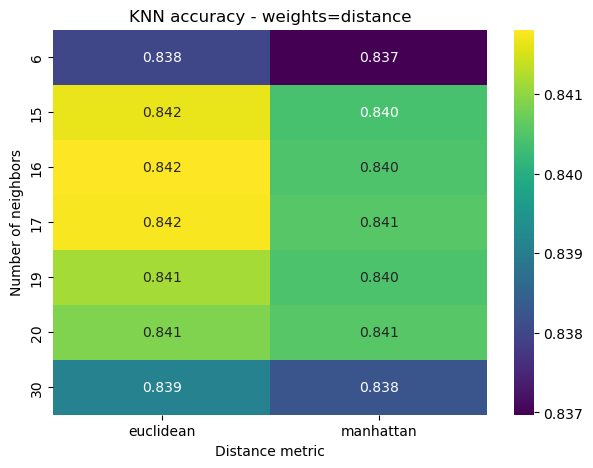

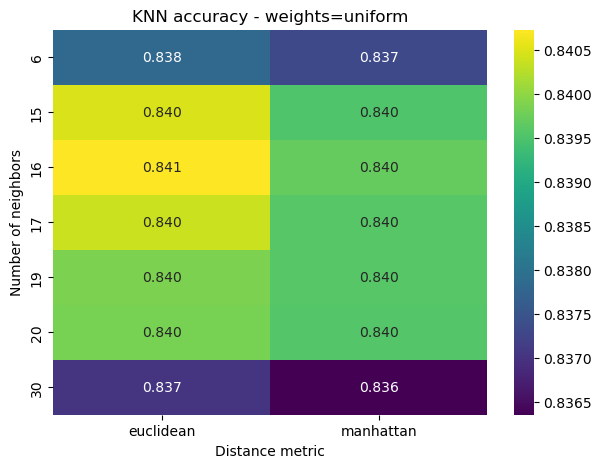

In [63]:
import seaborn as sns

# Plot each weight type separately
for weights in results["weights"].unique():
    subset = results[results["weights"] == weights]

    # Create a table:
    pivot = subset.pivot(
        index="n_neighbors", # rows = n_neighbors
        columns="metric", # columns = metric
        values="mean_accuracy" # values = mean CV accuracy
    )
    # Create heatmap
    plt.figure(figsize=(7, 5))

    sns.heatmap(
        pivot,
        annot=True,       # Show accuracy values
        fmt=".3f",        # Show 3 decimal places
        cmap="viridis"
    )

    plt.title(f"KNN accuracy - weights={weights}")
    plt.xlabel("Distance metric")
    plt.ylabel("Number of neighbors")

    plt.show()

In [64]:
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 
# Evaluate and Analyse best models performance working on test set
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 

tf = pd.read_csv("test_set3.csv", index_col=0) # Get training set

t_features = tf[["ax", "ay", "az", "gx", "gy", "gz"]]
t_activity = tf["label"]
t_groups = tf["recording_id"]

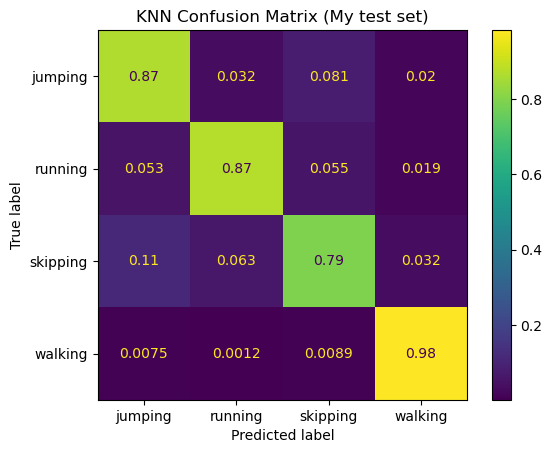

In [68]:
# Accuracy and Confusion matrix
# ========================================== 

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create predictions using GroupKFold
y_pred = best_model.predict(t_features)

# Display confusion matrix
disp = ConfusionMatrixDisplay.from_predictions(
    t_activity,
    y_pred,
    normalize="true"
)

plt.title("KNN Confusion Matrix (My test set)")
plt.show()

In [81]:
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 
# Generalize to another person's test set
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 

ben = pd.read_csv("Renamed_combined.csv", index_col=0) # Get training set

t_features = ben[["ax", "ay", "az", "gx", "gy", "gz"]]
t_activity = ben["label"]
t_groups = ben["recording_id"]


In [83]:
# Accuracy and Confusion matrix
# ========================================== 

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create predictions using GroupKFold
predictions = best_model.predict(t_features)


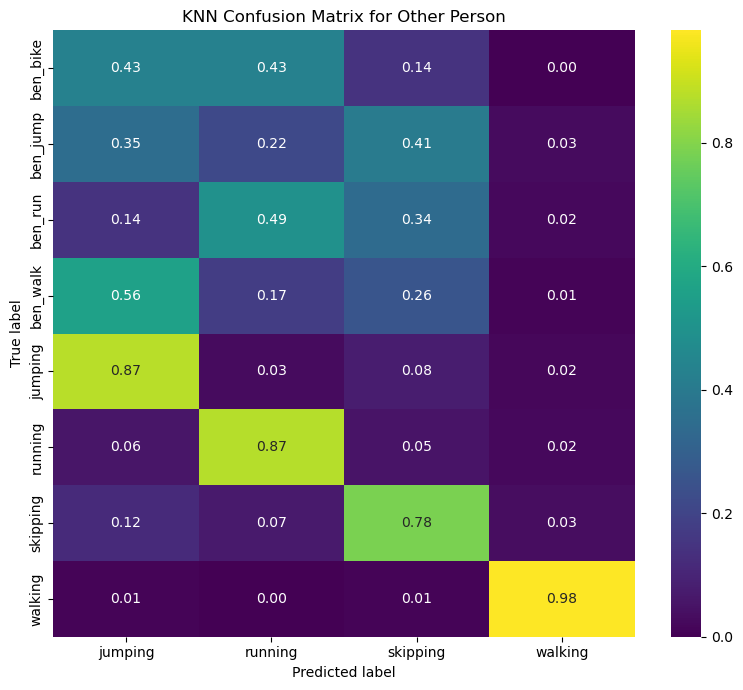

In [86]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

true_labels = [
    "ben_bike",
    "ben_jump",
    "ben_run",
    "ben_walk",
    "jumping",
    "running",
    "skipping",
    "walking"
]

trained_labels = [
    "jumping",
    "running",
    "skipping",
    "walking"
]

# Create an 8 x 4 confusion matrix
cm = np.zeros((len(true_labels), len(trained_labels)))

for i, true_label in enumerate(true_labels):
    for j, predicted_label in enumerate(trained_labels):
        cm[i, j] = np.sum(
            (t_activity == true_label) &
            (predictions == predicted_label)
        )

# Normalize each row
cm = cm / cm.sum(axis=1, keepdims=True)

# Plot
plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    xticklabels=trained_labels,
    yticklabels=true_labels,
    cmap="viridis"
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("KNN Confusion Matrix for Other Person")
plt.tight_layout()
plt.show()